# Level 3 — Two parameters and global bifurcations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/03_two-parameters-and-global-bifurcations.ipynb)

Follow bifurcation points themselves: curves of Hopf and fold points in two
parameters, with the special points on them (generalised Hopf, cusp). Then
meet *global* bifurcations, which no linearisation can see: a periodic orbit
that grows until it touches a saddle (a homoclinic orbit), and a travelling
front, which is an orbit joining two saddles (a heteroclinic orbit) found by
shooting.

| | model | what it shows |
|---|---|---|
| [16](#morris-lecar-bifurcation) | Morris–Lecar | one- and two-parameter diagrams, GH points |
| [17](#morris-lecar-homoclinic) | Morris–Lecar with a saddle | period blow-up at a homoclinic orbit |
| [18](#interacting-saddle-nodes) | interacting saddle-nodes | equilibria from a quartic, folds, Hopf at $\mu = 0$ |
| [19](#nagumo-front) | Nagumo front | front speed by shooting vs $(1 - 2a)/\sqrt{2}$ |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 16–19 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT and its AUTO
through pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.3.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="morris-lecar-bifurcation"></a>
## 16. Morris–Lecar: one- and two-parameter bifurcation diagrams

The Morris–Lecar neuron (time in ms, voltage in mV): a membrane potential $v$
with a fast calcium current and a slower potassium gating variable $w$,

$$
C\,\dot v = i + g_L\,(v_L - v) + g_K\,w\,(v_K - v) + g_{Ca}\,m_\infty(v)\,(v_{Ca} - v),
\qquad
\dot w = \phi\,\frac{w_\infty(v) - w}{\tau_w(v)},
$$

$$
m_\infty(v) = \tfrac12\Bigl(1 + \tanh\frac{v - v_1}{v_2}\Bigr), \qquad
w_\infty(v) = \tfrac12\Bigl(1 + \tanh\frac{v - v_3}{v_4}\Bigr), \qquad
\tau_w(v) = \frac{1}{\cosh\bigl((v - v_3)/(2v_4)\bigr)} .
$$

Parameters (the Hopf regime): $C = 20$, $v_K = -84$, $v_L = -60$,
$v_{Ca} = 120$, $g_K = 8$, $g_L = 2$, $g_{Ca} = 4.4$, $v_1 = -1.2$,
$v_2 = 18$, $v_3 = 2$, $v_4 = 30$, $\phi = 0.04$, and first $i = 60$.

This is the XPP Studio "figures" workflow done in code: the phase plane at
$i = 60$, the equilibria in $i$ with the periodic orbits born at the first
Hopf point HB1, and HB1 followed in two parameters $(i, \phi)$. Look for the
points on the Hopf curve where the first Lyapunov coefficient $\ell_1$ changes
sign: the generalised Hopf (GH) points, where the onset of firing switches
between soft (supercritical) and hard (subcritical).

In [3]:
section("16_morris-lecar-bifurcation")

### The model

`function` defines the helper functions $m_\infty$, $w_\infty$, $\tau_w$;
`aux` adds the calcium current as an extra output. $\phi$ must be among AUTO's
parameters for the two-parameter step, and *Sing pt ctrl* is tightened for
accurate Newton iterations and eigenvalues.

In [4]:
P = dict(i=60, c=20, vk=-84, vl=-60, vca=120, gk=8, gl=2, gca=4.4, v1=-1.2, v2=18, v3=2, v4=30, phi=0.04)
mb = (ModelBuilder("morris_lecar_figures")
      .comment("Morris-Lecar neuron, Hopf regime (Rinzel & Ermentrout)")
      .function("minf(v)", ".5*(1+tanh((v-v1)/v2))")
      .function("winf(v)", ".5*(1+tanh((v-v3)/v4))")
      .function("tauw(v)", "1/cosh((v-v3)/(2*v4))")
      .ode("v", "(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c")
      .ode("w", "phi*(winf(v)-w)/tauw(v)")
      .aux("ica", "gca*minf(v)*(v-vca)")
      .parameter(**P)
      .initial(v=-60, w=0.015)
      .option(total=400, dt=0.25, meth="rk4", bound=10000))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("i", "phi", "gca", "c", "gk", "gl", "v3", "v4")
m.buttons.numerics.sing_pt_ctrl(500, 1e-10, 1e-8)

# Morris-Lecar neuron, Hopf regime (Rinzel & Ermentrout)
minf(v)=.5*(1+tanh((v-v1)/v2))
winf(v)=.5*(1+tanh((v-v3)/v4))
tauw(v)=1/cosh((v-v3)/(2*v4))
v'=(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c
w'=phi*(winf(v)-w)/tauw(v)
aux ica=gca*minf(v)*(v-vca)
par i=60,c=20,vk=-84,vl=-60,vca=120,gk=8,gl=2,gca=4.4,v1=-1.2,v2=18,v3=2,v4=30,phi=0.04
init v=-60,w=0.015
@ total=400,dt=0.25,meth=rungekutta,bound=10000
done



'prompt  Maximum iterates : [100] -> 500\nprompt  Newton tolerance : [0.001] -> 1e-10\nprompt  Jacobian epsilon : [0.001] -> 1e-08\n'

### Phase plane at $i = 60$

The axes have very different scales ($v$ in tens of mV, $w$ between 0 and 1),
so the direction-field arrows are scaled in window units. All trajectories end
at the stable rest state.

equilibrium at i = 60: <Equilibrium stable V=-36.7547, W=0.0701982>  eigenvalues [-0.05494+0.06293j -0.05494-0.06293j]


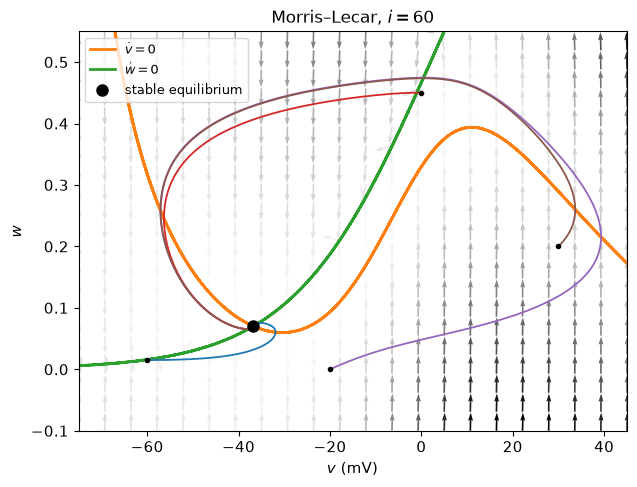

In [5]:
win = (-75, 45, -0.1, 0.55)
nc = m.nullclines(x="v", y="w", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=200)
X, Y, U, V = m.vector_field("v", "w", *win, grid=21)
eq = m.equilibrium({"v": -37, "w": 0.13})
print("equilibrium at i = 60:", eq, " eigenvalues", np.round(eq.eigenvalues, 5))

fig, ax = plt.subplots(figsize=(6.5, 5))
sx, sy = (win[1] - win[0]), (win[3] - win[2])
S = np.hypot(U / sx, V / sy)
ax.quiver(X, Y, U / sx / S, V / sy / S, S, cmap="Greys", scale=30, width=0.003, angles="xy")
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:orange", lw=2, label=r"$\dot v = 0$")
ax.plot(nc["W"][:, 0], nc["W"][:, 1], color="tab:green", lw=2, label=r"$\dot w = 0$")
for (v0, w0), col in zip([(-60, 0.015), (-20, 0.0), (0, 0.45), (30, 0.2)],
                         ["tab:blue", "tab:purple", "tab:red", "tab:brown"]):
    tr = m.run(keep=False, v=v0, w=w0, total=400)
    ax.plot(tr["v"], tr["w"], lw=1.3, color=col)
    ax.plot(v0, w0, "k.", ms=6)
ax.plot(eq.x["V"], eq.x["W"], "ko", ms=8, label="stable equilibrium")
ax.set(xlim=win[:2], ylim=win[2:], xlabel="$v$ (mV)", ylabel="$w$", title="Morris–Lecar, $i = 60$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "ml-phaseplane.png")

### Equilibria in $i$ and the orbits from HB1

Start from rest at $i = 0$ and follow the equilibrium up to $i = 300$, with
tighter AUTO tolerances ($10^{-6}$). There are two Hopf points; $\ell_1$ at
HB1 is positive, so HB1 is subcritical: the orbits born there are unstable
and turn around at a fold of periodic orbits before becoming stable. The
orbit branch is kept for one pass, from HB1 up to the branch point (BP) where
it reaches HB2.

HB1 at i = 93.85762: l1 = +0.00654 (subcritical); HB2 at i = 212.01881


folds of periodic orbits at i = [88.2933, 216.8998]


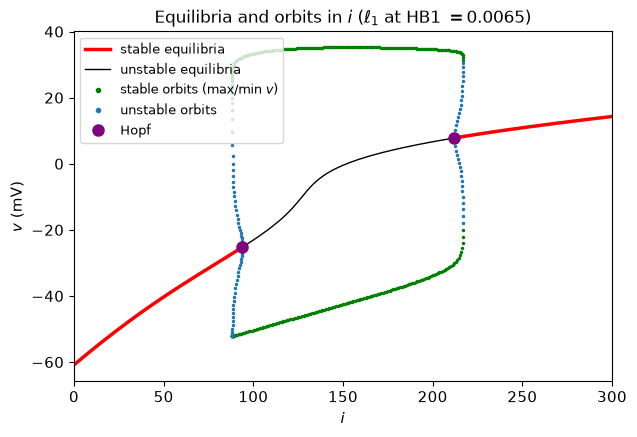

In [6]:
m.set(i=0)
m.run(total=1000)
m.run_last(total=10)
eqs = m.auto.run("i", start="steady", ds=0.5, dsmax=2, parmin=0, parmax=300, nmax=2000,
                 epsl=1e-6, epsu=1e-6, epss=1e-6)
hb1, hb2 = sorted(eqs.special("HB"), key=lambda p: p.x)
l1, om = m.auto.lyapunov(hb1)
print(f"HB1 at i = {hb1.x:.5f}: l1 = {l1:+.5f} ({'sub' if l1 > 0 else 'super'}critical); "
      f"HB2 at i = {hb2.x:.5f}")
po = list(m.auto.run(grab=hb1.label, choice="periodic", ntst=100, ds=0.2, dsmax=1, nmax=300))
po = po[:next(k for k, p in enumerate(po) if p.type == "BP") + 1]
print("folds of periodic orbits at i =", sorted({round(p.x, 4) for p in po if p.type == "LP"}))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
xs = np.array([p.x for p in eqs])
vs = np.array([p.u0["v"] for p in eqs])
st = np.array([bool(p.stable) for p in eqs])
ax.plot(xs, np.where(st, vs, np.nan), "r-", lw=2.5, label="stable equilibria")
ax.plot(xs, np.where(~st, vs, np.nan), "k-", lw=1, label="unstable equilibria")
px = np.array([p.x for p in po])
pst = np.array([bool(p.stable) for p in po])
for f in ("umax", "umin"):
    ys = np.array([getattr(p, f)["v"] for p in po])
    ax.plot(px[pst], ys[pst], "g.", ms=3)
    ax.plot(px[~pst], ys[~pst], ".", color="tab:blue", ms=3)
ax.plot([], [], "g.", label="stable orbits (max/min $v$)")
ax.plot([], [], ".", color="tab:blue", label="unstable orbits")
ax.plot([hb1.x, hb2.x], [hb1.u0["v"], hb2.u0["v"]], "o", color="purple", ms=8, label="Hopf")
ax.set(xlim=(0, 300), xlabel="$i$", ylabel="$v$ (mV)",
       title=rf"Equilibria and orbits in $i$ ($\ell_1$ at HB1 $= {l1:.4f}$)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "ml-bifurcation.png")

### HB1 in $(i, \phi)$

Grab HB1 and follow it with $\phi$ as second parameter (`choice="two param"`),
once in each direction. `m.auto.gh_points` returns the points on the curve
where $\ell_1 = 0$. Inside the Hopf curve the rest state is unstable.

Hopf curve: 2000 points, phi up to 0.3869; GH points: [(124.46, 0.3062), (165.69, 0.2538)]


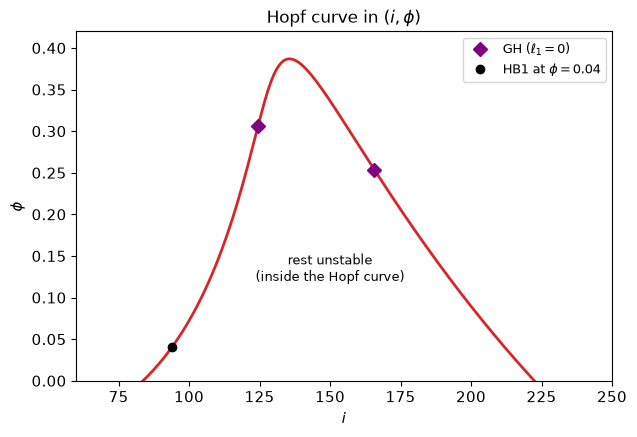

In [7]:
c1 = m.auto.run(grab=hb1.label, choice="two param", param2="phi", ds=0.5, dsmax=1, parmin=0, parmax=300,
                nmax=1000)
c2 = m.auto.run(grab=hb1.label, choice="two param", ds=-0.5)
gh = m.auto.gh_points(c1) + m.auto.gh_points(c2)
hopf = np.array([[q.x, q.par["phi"], q.u0["v"]] for c in (c1, c2) for q in c])
print(f"Hopf curve: {len(hopf)} points, phi up to {hopf[:, 1].max():.4f}; GH points:",
      [(round(g["par"], 2), round(g["par2"], 4)) for g in gh])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for c in (c1, c2):
    ax.plot([q.x for q in c], [q.par["phi"] for q in c], color="tab:red", lw=2)
ax.plot([g["par"] for g in gh], [g["par2"] for g in gh], "D", color="purple", ms=7, label=r"GH ($\ell_1 = 0$)")
ax.plot(hb1.x, P["phi"], "ko", ms=6, label=r"HB1 at $\phi = 0.04$")
ax.text(150, 0.12, "rest unstable\n(inside the Hopf curve)", ha="center", fontsize=9)
ax.set(xlim=(60, 250), ylim=(0, 0.42), xlabel="$i$", ylabel=r"$\phi$", title=r"Hopf curve in $(i, \phi)$")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "ml-twopar.png")

### Checks

On an equilibrium $w = w_\infty(v)$, so the current that holds the cell at
voltage $v$ is explicit:

$$
i(v) = -\Bigl[g_L\,(v_L - v) + g_K\,w_\infty(v)\,(v_K - v) + g_{Ca}\,m_\infty(v)\,(v_{Ca} - v)\Bigr].
$$

The trace of the Jacobian is $a_{11}(v) - \phi/\tau_w(v)$, where

$$
a_{11}(v) = \frac{1}{C}\Bigl[-g_L - g_K\,w_\infty(v) - g_{Ca}\,m_\infty(v)
+ g_{Ca}\,\frac{1 - \tanh^2\bigl((v - v_1)/v_2\bigr)}{2v_2}\,(v_{Ca} - v)\Bigr]
$$

is $\partial \dot v/\partial v$. So the Hopf curve is given parametrically by

$$
\bigl(i(v),\; \phi(v)\bigr), \qquad \phi(v) = a_{11}(v)\,\tau_w(v),
$$

(with $\det J > 0$). We check the equilibrium at $i = 60$ (by solving
$i(v) = 60$ on a fine grid) and $w = w_\infty(v)$; every point of AUTO's Hopf
curve against $i(v)$ and $\phi(v)$; the top of the curve, the largest
$\phi(v)$; and its two ends: as $\phi \to 0$ the Hopf points tend to the knees
of the $\dot v = 0$ nullcline, where $a_{11} = 0$. Finally, HB1 is subcritical
($\ell_1 > 0$) at $\phi = 0.04$.

In [8]:
th = lambda v, a, b: np.tanh((v - a) / b)
minf = lambda v: 0.5 * (1 + th(v, P["v1"], P["v2"]))
winf = lambda v: 0.5 * (1 + th(v, P["v3"], P["v4"]))
tauw = lambda v: 1 / np.cosh((v - P["v3"]) / (2 * P["v4"]))
i_of = lambda v: -(P["gl"] * (P["vl"] - v) + P["gk"] * winf(v) * (P["vk"] - v)
                   + P["gca"] * minf(v) * (P["vca"] - v))
a11 = lambda v: (-P["gl"] - P["gk"] * winf(v) - P["gca"] * minf(v)
                 + P["gca"] * (1 - th(v, P["v1"], P["v2"])**2) / (2 * P["v2"]) * (P["vca"] - v)) / P["c"]
phi_of = lambda v: a11(v) * tauw(v)
vg = np.linspace(-60, 40, 200001)
v60 = vg[np.argmin(abs(i_of(vg) - 60))]
check("equilibrium v at i = 60 (exact, grid 5e-4 mV)", eq.x["V"], v60, 1e-3)
check("equilibrium w = winf(v)", eq.x["W"], winf(eq.x["V"]), 1e-8)
check("Hopf curve: largest |i_AUTO - i(v)|", np.abs(hopf[:, 0] - i_of(hopf[:, 2])).max(), 0, 1e-3)
check("Hopf curve: largest |phi_AUTO - phi(v)|", np.abs(hopf[:, 1] - phi_of(hopf[:, 2])).max(), 0, 1e-6)
check("top of the Hopf curve: largest phi (exact)", hopf[:, 1].max(), phi_of(vg).max(), 1e-4)
knees = sorted(i_of(vg[1:][np.sign(a11(vg[:-1])) != np.sign(a11(vg[1:]))]))
ends = sorted(q[-1].x for q in (c1, c2))
check("Hopf curve end as phi -> 0, left knee (exact)", ends[0], knees[0], 0.01)
check("Hopf curve end as phi -> 0, right knee (exact)", ends[1], knees[1], 0.01)
check("HB1 is subcritical at phi = 0.04 (1 = l1 > 0)", float(l1 > 0), 1, 0)
checks_done()

  ok   equilibrium v at i = 60 (exact, grid 5e-4 mV): -36.7547 (expected -36.7545)
  ok   equilibrium w = winf(v): 0.0701982 (expected 0.0701982)
  ok   Hopf curve: largest |i_AUTO - i(v)|: 2.22028e-05 (expected 0)
  ok   Hopf curve: largest |phi_AUTO - phi(v)|: 3.52676e-07 (expected 0)
  ok   top of the Hopf curve: largest phi (exact): 0.386881 (expected 0.38693)
  ok   Hopf curve end as phi -> 0, left knee (exact): 83.6473 (expected 83.6466)
  ok   Hopf curve end as phi -> 0, right knee (exact): 222.452 (expected 222.456)
  ok   HB1 is subcritical at phi = 0.04 (1 = l1 > 0): 1 (expected 1)

16_morris-lecar-bifurcation: 8/8 checks passed


<a id="morris-lecar-homoclinic"></a>
## 17. Morris–Lecar with a saddle: a homoclinic orbit

The same Morris–Lecar equations as in section 16,

$$
C\,\dot v = i + g_L\,(v_L - v) + g_K\,w\,(v_K - v) + g_{Ca}\,m_\infty(v)\,(v_{Ca} - v),
\qquad
\dot w = \phi\,\frac{w_\infty(v) - w}{\tau_w(v)},
$$

but now with $g_{Ca} = 4$, $\phi = 0.23$, $v_3 = 12$, $v_4 = 17.4$ (the other
parameters as before, first $i = 37$). Over a range of $i$ there are three
equilibria: a stable node (rest), a saddle and a focus. The periodic orbit
born at the Hopf point of the focus grows until it touches the saddle at
$i_{\mathrm{hom}} \approx 35.0067$: a homoclinic bifurcation. Close to it the
orbit spends longer and longer near the saddle, and its period grows like

$$
T \approx T_0 - \frac{1}{\lambda_u}\,\ln\bigl(i - i_{\mathrm{hom}}\bigr),
$$

where $\lambda_u$ is the saddle's unstable eigenvalue.

We follow the equilibria (a fold and a Hopf point), follow the periodic orbits
down to the homoclinic orbit, fit the logarithmic law, and see the long-period
orbit pass close to the saddle in a plain simulation.

In [9]:
section("17_morris-lecar-homoclinic")

### The model

In [10]:
P = dict(i=37, c=20, vk=-84, vl=-60, vca=120, gk=8, gl=2, gca=4, v1=-1.2, v2=18, v3=12, v4=17.4, phi=0.23)
mb = (ModelBuilder("morris_lecar_homoclinic")
      .comment("Morris-Lecar with a saddle: a homoclinic orbit of the saddle")
      .function("minf(v)", ".5*(1+tanh((v-v1)/v2))")
      .function("winf(v)", ".5*(1+tanh((v-v3)/v4))")
      .function("tauw(v)", "1/cosh((v-v3)/(2*v4))")
      .ode("v", "(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c")
      .ode("w", "phi*(winf(v)-w)/tauw(v)")
      .parameter(**P)
      .initial(v=-60, w=0.015)
      .option(total=400, dt=0.25, bound=10000))
print(mb.render())
m = mb.load(ODE)
m.buttons.numerics.sing_pt_ctrl(500, 1e-10, 1e-8)

# Morris-Lecar with a saddle: a homoclinic orbit of the saddle
minf(v)=.5*(1+tanh((v-v1)/v2))
winf(v)=.5*(1+tanh((v-v3)/v4))
tauw(v)=1/cosh((v-v3)/(2*v4))
v'=(i+gl*(vl-v)+gk*w*(vk-v)+gca*minf(v)*(vca-v))/c
w'=phi*(winf(v)-w)/tauw(v)
par i=37,c=20,vk=-84,vl=-60,vca=120,gk=8,gl=2,gca=4,v1=-1.2,v2=18,v3=12,v4=17.4,phi=0.23
init v=-60,w=0.015
@ total=400,dt=0.25,bound=10000
done



'prompt  Maximum iterates : [100] -> 500\nprompt  Newton tolerance : [0.001] -> 1e-10\nprompt  Jacobian epsilon : [0.001] -> 1e-08\n'

### AUTO: equilibria in $i$

Settle on the stable node at $i = 37$ and follow it in $i$. The branch is
S-shaped: we keep the fold (LP) at positive $i$, where the node meets the
saddle, and the Hopf point of the focus.

In [11]:
m.run(total=2000)
m.run_last(total=10)
eqs = m.auto.run("i", start="steady", ds=0.1, dsmax=0.5, parmin=-30, parmax=60, nmax=3000,
                 epsl=1e-6, epsu=1e-6, epss=1e-6)
lp = [p for p in eqs.special("LP") if p.x > 0][0]
hb = eqs.special("HB")[0]
l1, om = m.auto.lyapunov(hb)
print(f"fold (saddle-node) at i = {lp.x:.5f}; Hopf at i = {hb.x:.5f}, l1 = {l1:+.5f}")

fold (saddle-node) at i = 39.96315; Hopf at i = 36.31622, l1 = +0.00099


### AUTO: periodic orbits from the Hopf point to the homoclinic orbit

The branch of orbits first turns at a fold of orbits, then runs down in $i$
towards the homoclinic orbit while the period blows up. We keep the way down
(after the fold) and drop AUTO's last points with absurd periods
($T > 10^4$); the orbit with the longest period sits at $i_{\mathrm{hom}}$.

In [12]:
po = m.auto.run(grab=hb.label, choice="periodic", ntst=100, ds=-0.02, dsmax=0.2, nmax=600)
x = np.array([p.x for p in po])
T = np.array([p.period for p in po])
k_lp = next(k for k, p in enumerate(po) if p.type == "LP")
good = (T < 1e4) & (np.arange(len(po)) > k_lp)
i_hom = x[good].min()
print(f"{len(po)} orbits; longest period {T[good].max():.0f} ms; homoclinic at i = {i_hom:.7f}")

265 orbits; longest period 8648 ms; homoclinic at i = 35.0067342


### The logarithmic law

Find the saddle at $i = 37$ and follow it by Newton's method to
$i_{\mathrm{hom}}$; its eigenvalues are $\lambda_u > 0 > \lambda_s$. Then fit
$T = T_0 - b\ln(i - i_{\mathrm{hom}})$ where the law holds and
$i - i_{\mathrm{hom}}$ is well resolved ($80 < T < 250$ ms); the slope $b$
should be $1/\lambda_u$.

saddle at i_hom: v = -22.3157, eigenvalues 0.08450, -0.30858
fit: T = 37.876 - 11.8261 ln(i - i_hom)   (1/lambda_u = 11.8347)


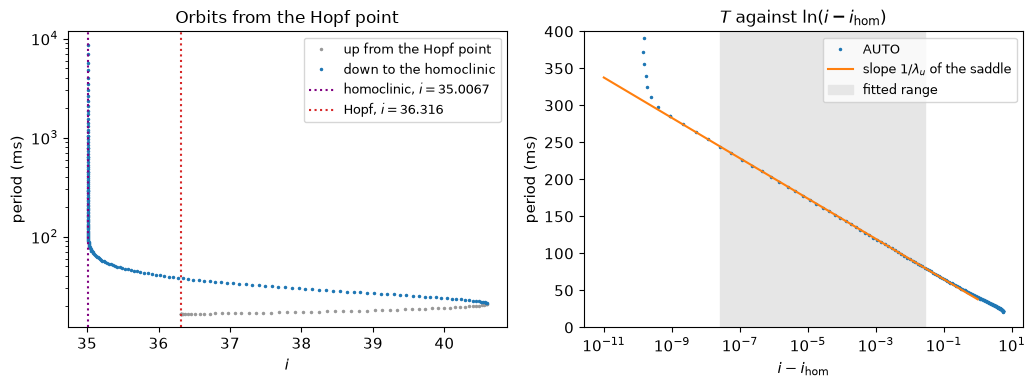

In [13]:
sad = m.equilibrium({"v": -22, "w": 0.02})
m.set(i=i_hom)
sad = m.equilibrium(sad.x)
lam_u = sad.eigenvalues.real.max()
lam_s = sad.eigenvalues.real.min()
print(f"saddle at i_hom: v = {sad.x['V']:.4f}, eigenvalues {lam_u:.5f}, {lam_s:.5f}")
fit = good & (T > 80) & (T < 250) & (x > i_hom)
b, C = np.polyfit(-np.log(x[fit] - i_hom), T[fit], 1)
print(f"fit: T = {C:.3f} - {b:.4f} ln(i - i_hom)   (1/lambda_u = {1 / lam_u:.4f})")

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
axs[0].semilogy(x[:k_lp + 1], T[:k_lp + 1], ".", color="0.6", ms=3, label="up from the Hopf point")
axs[0].semilogy(x[good], T[good], ".", color="tab:blue", ms=3, label="down to the homoclinic")
axs[0].axvline(i_hom, color="purple", ls=":", label=rf"homoclinic, $i = {i_hom:.4f}$")
axs[0].axvline(hb.x, color="tab:red", ls=":", label=rf"Hopf, $i = {hb.x:.3f}$")
axs[0].set(xlabel="$i$", ylabel="period (ms)", title="Orbits from the Hopf point")
axs[0].legend()
d = np.logspace(-11, 0, 50)
s = good & (x > i_hom)
axs[1].semilogx(x[s] - i_hom, T[s], ".", color="tab:blue", ms=3, label="AUTO")
axs[1].semilogx(d, C - np.log(d) / lam_u, "-", color="tab:orange", lw=1.5,
                label=r"slope $1/\lambda_u$ of the saddle")
axs[1].axvspan((x[fit] - i_hom).min(), (x[fit] - i_hom).max(), color="0.9", zorder=0, label="fitted range")
axs[1].set(xlabel=r"$i - i_{\mathrm{hom}}$", ylabel="period (ms)", ylim=(0, 400),
           title=r"$T$ against $\ln(i - i_{\mathrm{hom}})$")
axs[1].legend()
fig.tight_layout()
fig.savefig(FIG / "period.png")

### Phase plane at $i = 35.01$

Just above the homoclinic point, a plain simulation settles on a stable orbit
that passes close to the saddle, with a long period (measured from upward
crossings of $v = 0$).

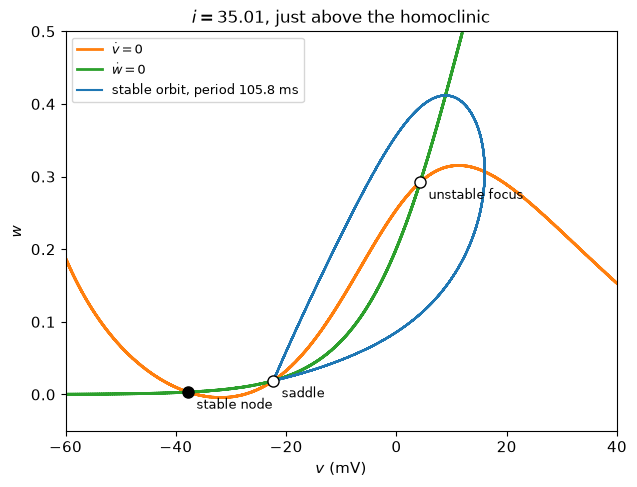

In [14]:
m.set(i=35.01)
win = (-60, 40, -0.05, 0.5)
nc = m.nullclines(x="v", y="w", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=300)
cyc = m.run(keep=False, v=0, w=0.3, total=3000, trans=2000)
vv = cyc["v"]
ups = cyc.t[1:][(vv[:-1] < 0) & (vv[1:] >= 0)]
T_sim = np.diff(ups).mean()
eq3 = [m.equilibrium(g) for g in ({"v": -36, "w": 0.004}, {"v": -22, "w": 0.02}, {"v": 4, "w": 0.3})]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:orange", lw=2, label=r"$\dot v = 0$")
ax.plot(nc["W"][:, 0], nc["W"][:, 1], color="tab:green", lw=2, label=r"$\dot w = 0$")
ax.plot(cyc["v"], cyc["w"], color="tab:blue", lw=1.5, label=f"stable orbit, period {T_sim:.1f} ms")
for e, name in zip(eq3, ("stable node", "saddle", "unstable focus")):
    ax.plot(e.x["V"], e.x["W"], "o", mfc="k" if e.stable else "white", mec="k", ms=8)
    ax.annotate(name, (e.x["V"], e.x["W"]), xytext=(6, -12), textcoords="offset points", fontsize=9)
ax.set(xlim=win[:2], ylim=win[2:], xlabel="$v$ (mV)", ylabel="$w$",
       title="$i = 35.01$, just above the homoclinic")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### Checks

As in section 16, on an equilibrium $w = w_\infty(v)$ and $i(v)$ is explicit.

* The fold of equilibria is where $di/dv = 0$: the largest $i(v)$ on the lower
  part of the S ($-40 < v < -10$).
* The Hopf point is where the trace $a_{11}(v) - \phi/\tau_w(v)$ vanishes
  (for $v > 0$).
* The homoclinic point agrees with XPP Studio's value $35.0067$.
* The slope of $T$ against $-\ln(i - i_{\mathrm{hom}})$ equals $1/\lambda_u$
  (to 1%).
* The saddle quantity $\lambda_u + \lambda_s < 0$, so by
  Andronov–Leontovich the orbits next to the homoclinic orbit are stable
  (AUTO's Floquet multipliers are unreliable there; the simulation shows it).
* The period of the simulated orbit at $i = 35.01$ equals AUTO's (to 0.25 ms).

In [15]:
th = lambda v, a, b: np.tanh((v - a) / b)
minf = lambda v: 0.5 * (1 + th(v, P["v1"], P["v2"]))
winf = lambda v: 0.5 * (1 + th(v, P["v3"], P["v4"]))
tauw = lambda v: 1 / np.cosh((v - P["v3"]) / (2 * P["v4"]))
i_of = lambda v: -(P["gl"] * (P["vl"] - v) + P["gk"] * winf(v) * (P["vk"] - v)
                   + P["gca"] * minf(v) * (P["vca"] - v))
a11 = lambda v: (-P["gl"] - P["gk"] * winf(v) - P["gca"] * minf(v)
                 + P["gca"] * (1 - th(v, P["v1"], P["v2"])**2) / (2 * P["v2"]) * (P["vca"] - v)) / P["c"]
vg = np.linspace(-60, 40, 400001)
ig = i_of(vg)
check("fold of equilibria (exact, largest i on the S below)", lp.x, ig[(vg > -40) & (vg < -10)].max(), 1e-4)
trc = a11(vg) - P["phi"] / tauw(vg)
k = np.where((np.sign(trc[:-1]) != np.sign(trc[1:])) & (vg[:-1] > 0))[0][0]
check("Hopf point (exact, trace = 0)", hb.x, ig[k], 1e-3)
check("homoclinic i (XPP Studio: 35.0067)", i_hom, 35.0067, 1e-4)
check("slope of T against -ln(i - i_hom) vs 1/lambda_u", b, 1 / lam_u, 0.01 / lam_u)
check("saddle quantity lambda_u + lambda_s < 0 (1 = yes)", float(lam_u + lam_s < 0), 1, 0)
check("period at i = 35.01: simulation vs AUTO (ms)", T_sim, np.interp(35.01, x[s][::-1], T[s][::-1]), 0.25)
checks_done()

  ok   fold of equilibria (exact, largest i on the S below): 39.9632 (expected 39.9632)
  ok   Hopf point (exact, trace = 0): 36.3162 (expected 36.3161)
  ok   homoclinic i (XPP Studio: 35.0067): 35.0067 (expected 35.0067)
  ok   slope of T against -ln(i - i_hom) vs 1/lambda_u: 11.8261 (expected 11.8347)
  ok   saddle quantity lambda_u + lambda_s < 0 (1 = yes): 1 (expected 1)
  ok   period at i = 35.01: simulation vs AUTO (ms): 105.781 (expected 105.613)

17_morris-lecar-homoclinic: 6/6 checks passed


<a id="interacting-saddle-nodes"></a>
## 18. Interacting saddle-nodes

From Ashwin, Postlethwaite and Sieber (Nonlinearity 2026,
DOI 10.1088/1361-6544/ae788a):

$$
\dot x = x^2 - \lambda + 2\alpha\,y - \gamma, \qquad
\dot y = y^2 - \lambda + 2\beta\,x + \gamma,
$$

$$
\lambda = \mu + \frac{\gamma\,(\gamma + \alpha^2 - \beta^2)}{(\alpha + \beta)^2},
$$

with $\gamma = 3.58$, $\alpha = 3.1$, $\beta = -1.3$ and first
$\mu = -0.005$. Both nullclines are parabolas, so there are up to four
equilibria, and they appear and disappear in pairs at saddle-node
bifurcations. The shift built into $\lambda$ puts a Hopf point exactly at
$\mu = 0$, between two saddle-nodes close by.

We draw the phase plane, count the equilibria against $\mu$ from an exact
quartic, follow them with AUTO, and check folds and Hopf point against exact
values.

In [16]:
section("18_interacting-saddle-nodes")

### The model

`fixed("lambda", ...)` defines $\lambda$ as a fixed quantity computed from
the parameters. The model is integrated with Dormand–Prince 5 (XPP's `5dp`)
and `bound=10` (XPP reads only the first letter of `meth`, so `dopri5` or
`dormprince` would make it a discrete map).

Eliminating $y = (s - x^2)/(2\alpha)$, with $s = \lambda + \gamma$, from
$\dot x = 0$ and putting it into $\dot y = 0$ gives a quartic for $x$:

$$
x^4 - 2s\,x^2 + 8\alpha^2\beta\,x + s^2 + 4\alpha^2(\gamma - \lambda) = 0 .
$$

`exact_equilibria(mu)` returns its real roots.

In [17]:
g, a, b = 3.58, 3.1, -1.3
shift = g * (g + a**2 - b**2) / (a + b)**2
mb = (ModelBuilder("interacting_saddle_nodes")
      .comment("Interacting saddle-nodes (Ashwin, Postlethwaite and Sieber, Nonlinearity 2026)")
      .parameter(mu=-0.005, gamma=g)
      .parameter(alpha=a, beta=b)
      .fixed("lambda", "mu + gamma*(gamma+alpha^2-beta^2)/(alpha+beta)^2")
      .ode("x", "x^2-lambda+2*alpha*y-gamma")
      .ode("y", "y^2-lambda+2*beta*x+gamma")
      .initial(x=1, y=1)
      .option(meth="5dp", total=10, dt=0.01, toler=1e-6, bound=10))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("mu", "gamma", "alpha", "beta")
m.buttons.numerics.sing_pt_ctrl(500, 1e-10, 1e-8)


def exact_equilibria(mu):
    lam = mu + shift
    s = lam + g
    r = np.roots([1, 0, -2 * s, 8 * a**2 * b, s**2 + 4 * a**2 * (g - lam)])
    x = np.sort(r[abs(r.imag) < 1e-9].real)
    return x, (s - x**2) / (2 * a)

# Interacting saddle-nodes (Ashwin, Postlethwaite and Sieber, Nonlinearity 2026)
par mu=-0.005,gamma=3.58
par alpha=3.1,beta=-1.3
lambda=mu + gamma*(gamma+alpha^2-beta^2)/(alpha+beta)^2
x'=x^2-lambda+2*alpha*y-gamma
y'=y^2-lambda+2*beta*x+gamma
init x=1,y=1
@ meth=5dp,total=10,dt=0.01,toler=1e-06,bound=10
done



### Phase plane at $\mu = -0.005$

XPP's Newton method from each root of the quartic gives the four equilibria;
`kind` classifies them by their eigenvalues. Three lie close together (a
node, a saddle and an unstable focus), so the right panel zooms in.
Trajectories stop early if $|x|$ or $|y|$ passes 10 (`bound`).

equilibria at mu = -0.005:
  x = -2.676954, y = +1.470275  stable node, eigenvalues [-2.2457+0.j -0.1677+0.j]
  x = -2.340909, y = +1.742247  saddle, eigenvalues [-1.3417+0.j  0.1444+0.j]
  x = -1.957148, y = +2.008284  unstable focus, eigenvalues [0.0511+0.6288j 0.0511-0.6288j]
  x = +6.975012, y = -5.220807  saddle, eigenvalues [13.2702+0.j -9.7618+0.j]


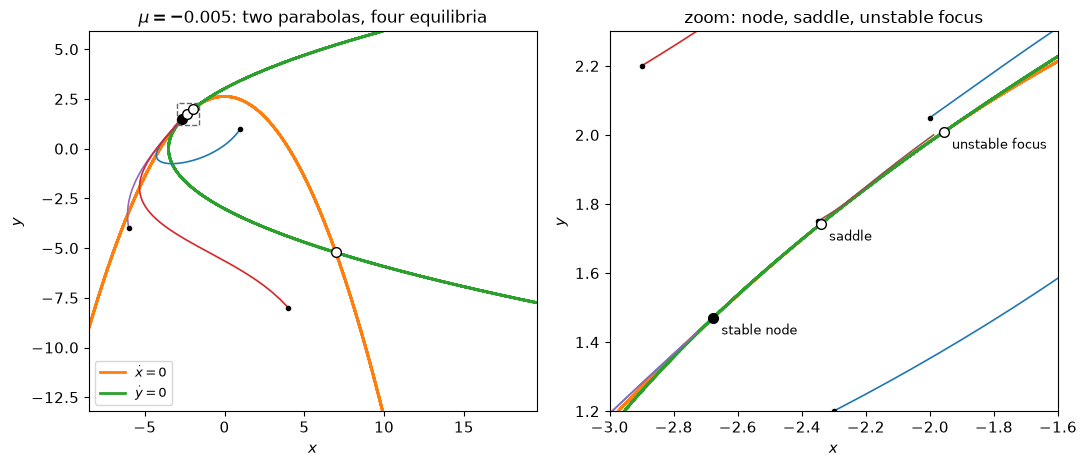

In [18]:
ex, ey = exact_equilibria(-0.005)
eqs = [m.equilibrium({"x": x, "y": y}) for x, y in zip(ex, ey)]
kind = lambda e: ("saddle" if np.prod(e.eigenvalues.real) < 0 else
                  ("stable " if e.stable else "unstable ") + ("focus" if abs(e.eigenvalues.imag).max() > 0 else "node"))
print("equilibria at mu = -0.005:")
for e in eqs:
    print(f"  x = {e.x['X']:+.6f}, y = {e.x['Y']:+.6f}  {kind(e)}, eigenvalues {np.round(e.eigenvalues, 4)}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, win in zip(axs, ((-8.5, 19.6, -13.2, 5.9), (-3.0, -1.6, 1.2, 2.3))):
    nc = m.nullclines(x="x", y="y", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=300)
    ax.plot(nc["X"][:, 0], nc["X"][:, 1], color="tab:orange", lw=2, label=r"$\dot x = 0$")
    ax.plot(nc["Y"][:, 0], nc["Y"][:, 1], color="tab:green", lw=2, label=r"$\dot y = 0$")
    ax.set(xlim=win[:2], ylim=win[2:], xlabel="$x$", ylabel="$y$")
starts = [((1, 1), axs[0]), ((-6, -4), axs[0]), ((4, -8), axs[0]),
          ((-2.0, 2.05), axs[1]), ((-2.3, 1.2), axs[1]), ((-2.9, 2.2), axs[1]), ((-2.35, 1.75), axs[1])]
for ((x0, y0), ax), col in zip(starts, ["tab:blue", "tab:purple", "tab:red", "tab:blue", "tab:purple",
                                        "tab:red", "tab:brown"]):
    tr = m.run(keep=False, x=x0, y=y0, total=10)
    ax.plot(tr["x"], tr["y"], color=col, lw=1.2)
    ax.plot(x0, y0, "k.", ms=6)
for ax in axs:
    for e in eqs:
        ax.plot(e.x["X"], e.x["Y"], "o", mfc="k" if e.stable else "white", mec="k", ms=7)
axs[0].add_patch(plt.Rectangle((-3.0, 1.2), 1.4, 1.1, fill=False, ls="--", color="0.4"))
axs[0].set_title(r"$\mu = -0.005$: two parabolas, four equilibria")
axs[0].legend(loc="lower left")
axs[1].set_title("zoom: node, saddle, unstable focus")
for e in eqs[:3]:
    axs[1].annotate(kind(e), (e.x["X"], e.x["Y"]), xytext=(6, -12), textcoords="offset points", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### Equilibria against $\mu$: exact count, and AUTO from the saddle

Start AUTO at the saddle (made the current state by a tiny run) and follow it
in $\mu$ in both directions. The branch has two folds (LP) and the Hopf point
between them. Below, the number of real roots of the quartic against $\mu$
jumps $2 \to 4 \to 2$ at the folds.

AUTO: folds at mu = -0.0130992 and 0.0073099; Hopf at mu = -4.25e-07


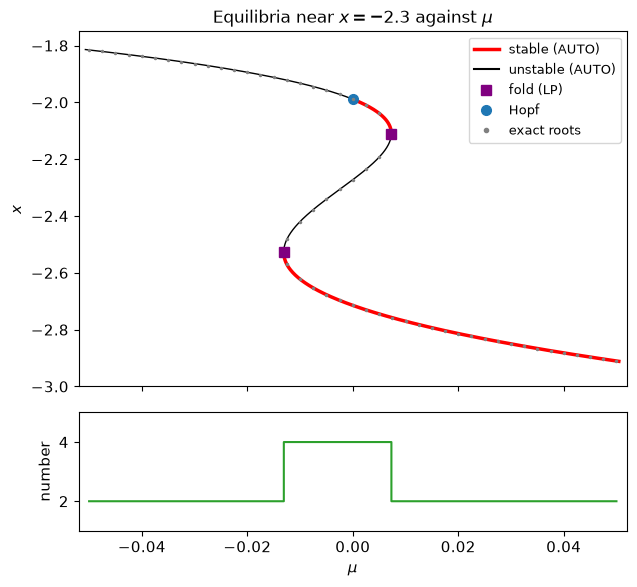

In [19]:
e0 = eqs[1]
parts = []
for sign in (1, -1):
    m.auto.reset()
    m.set(mu=-0.005, x=e0.x["X"], y=e0.x["Y"])
    m.run(total=1e-4)
    parts.append(m.auto.run("mu", start="steady", ds=sign * 0.0005, dsmax=0.002,
                            parmin=-0.05, parmax=0.05, nmax=2000))
lps = sorted((p for d in parts for p in d.special("LP")), key=lambda p: p.x)
hb = [p for d in parts for p in d.special("HB")][0]
print(f"AUTO: folds at mu = {lps[0].x:.7f} and {lps[1].x:.7f}; Hopf at mu = {hb.x:.2e}")

mus = np.linspace(-0.05, 0.05, 2001)
count = np.array([len(exact_equilibria(u)[0]) for u in mus])
fig, axs = plt.subplots(2, 1, figsize=(6.5, 6), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
for d in parts:
    xs = np.array([p.x for p in d])
    us = np.array([p.u0["x"] for p in d])
    st = np.array([bool(p.stable) for p in d])
    axs[0].plot(xs, np.where(st, us, np.nan), "r-", lw=2.5)
    axs[0].plot(xs, np.where(~st, us, np.nan), "k-", lw=1)
axs[0].plot([], [], "r-", lw=2.5, label="stable (AUTO)")
axs[0].plot([], [], "k-", label="unstable (AUTO)")
axs[0].plot([p.x for p in lps], [p.u0["x"] for p in lps], "s", color="purple", ms=7, label="fold (LP)")
axs[0].plot(hb.x, hb.u0["x"], "o", color="tab:blue", ms=7, label="Hopf")
sel = mus[::50]
for u in sel:
    xr = exact_equilibria(u)[0]
    axs[0].plot([u] * len(xr[xr < 0]), xr[xr < 0], ".", color="0.5", ms=3)
axs[0].plot([], [], ".", color="0.5", label="exact roots")
axs[0].set(ylabel="$x$", ylim=(-3.0, -1.75), title=r"Equilibria near $x = -2.3$ against $\mu$")
axs[0].legend(loc="upper right")
axs[1].step(mus, count, where="mid", color="tab:green")
axs[1].set(xlabel=r"$\mu$", ylabel="number", xlim=(-0.052, 0.052), ylim=(1, 5), yticks=[2, 4])
fig.tight_layout()
fig.savefig(FIG / "equilibria_mu.png")

### Checks

* XPP's equilibria satisfy both equations (residual below $10^{-10}$), agree
  with the roots of the quartic, and there are four at $\mu = -0.005$.
* Folds: a double root of the quartic $Q(x)$ needs $Q = Q' = 0$. $Q' = 0$
  gives $s = x^2 + 2\alpha^2\beta/x$, and then $Q = 0$ becomes

$$
-x^4 + 2\beta\,x^3 + 2\gamma\,x^2 - 2\alpha^2\beta\,x + \alpha^2\beta^2 = 0,
$$

  whose roots give $\mu = s - \gamma - \text{shift}$ at the two folds near
  $\mu = 0$. The count of equilibria jumps twice.
* Hopf: on $y = -x$ the trace $2x + 2y$ vanishes; the equations then give
  $x = -\gamma/(\alpha + \beta)$ and $\lambda = \text{shift}$, so $\mu = 0$.
  The determinant $4(xy - \alpha\beta)$ gives the frequency

$$
\omega = 2\sqrt{-\alpha\beta - x^2}, \qquad x = -\frac{\gamma}{\alpha + \beta}.
$$

In [20]:
res = max(max(abs(e.x["X"]**2 - (-0.005 + shift) + 2 * a * e.x["Y"] - g),
              abs(e.x["Y"]**2 - (-0.005 + shift) + 2 * b * e.x["X"] + g)) for e in eqs)
check("XPP equilibria: largest residual of the two equations", res, 0, 1e-10)
check("XPP equilibria vs quartic roots (largest |dx|)", max(abs(e.x["X"] - x) for e, x in zip(eqs, ex)), 0, 1e-10)
check("number of equilibria at mu = -0.005", len(eqs), 4, 0)
xr = np.roots([-1, 2 * b, 2 * g, -2 * a**2 * b, a**2 * b**2])
mu_sn = np.sort([x**2 + 2 * a**2 * b / x - g - shift for x in xr.real[abs(xr.imag) < 1e-12]])
mu_sn = mu_sn[abs(mu_sn) < 0.05]
check("fold 1 in mu (exact)", lps[0].x, mu_sn[0], 1e-6)
check("fold 2 in mu (exact)", lps[1].x, mu_sn[1], 1e-6)
check("count jumps 2 -> 4 -> 2 at the folds (sum of |jumps| / 2)", np.abs(np.diff(count)).sum() / 2, 2, 0)
xh = -g / (a + b)
check("Hopf in mu (exact 0)", hb.x, 0, 1e-5)
check("Hopf x = -gamma/(alpha+beta) (exact)", hb.u0["x"], xh, 1e-4)
check("Hopf frequency (exact)", m.auto.lyapunov(hb)[1], 2 * np.sqrt(-a * b - xh**2), 1e-4)
checks_done()

  ok   XPP equilibria: largest residual of the two equations: 5.32907e-15 (expected 0)
  ok   XPP equilibria vs quartic roots (largest |dx|): 9.76996e-14 (expected 0)
  ok   number of equilibria at mu = -0.005: 4 (expected 4)
  ok   fold 1 in mu (exact): -0.0130992 (expected -0.0130992)
  ok   fold 2 in mu (exact): 0.00730989 (expected 0.00730989)
  ok   count jumps 2 -> 4 -> 2 at the folds (sum of |jumps| / 2): 2 (expected 2)
  ok   Hopf in mu (exact 0): -4.24549e-07 (expected 0)
  ok   Hopf x = -gamma/(alpha+beta) (exact): -1.98889 (expected -1.98889)


  ok   Hopf frequency (exact): 0.545238 (expected 0.545238)

18_interacting-saddle-nodes: 9/9 checks passed


<a id="nagumo-front"></a>
## 19. Nagumo travelling front: shooting for a heteroclinic orbit

The bistable cable equation

$$
\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2} + u\,(1 - u)\,(u - a)
$$

has fronts that turn the state $u = 1$ into $u = 0$ (or back), travelling at a
fixed speed $c$. In the moving frame $z = x - ct$ a front $u(z)$ solves
$u'' + c\,u' + u(1-u)(u-a) = 0$, written as a first-order system

$$
u' = v, \qquad v' = -c\,v - u\,(1 - u)\,(u - a),
$$

where $'$ is $d/dz$; first $a = 0.25$. Both $(1, 0)$ and $(0, 0)$ are
saddles, and a front is an orbit leaving one and landing on the other: a
heteroclinic orbit, which exists only for one value of $c$. The exact answer
(Huxley's front) is

$$
c = \frac{1 - 2a}{\sqrt{2}}, \qquad u(z) = \frac{1}{1 + e^{z/\sqrt{2}}} .
$$

We find the speed by shooting from the saddle at $(1, 0)$ and bisecting on
$c$, repeat it for several $a$, and compare the orbit and the front profile
with the exact ones.

In [21]:
section("19_nagumo-front")

### The model

The Jacobian step for eigenvalues is set from Python (XPP 8.1 ignores
`@ jac_eps` in the file).

In [22]:
mb = (ModelBuilder("nagumo_front")
      .comment("Nagumo front in the moving frame: u'' + c u' + u(1-u)(u-a) = 0")
      .ode("u", "v")
      .ode("v", "-c*v-u*(1-u)*(u-a)")
      .parameter(c=0.3, a=0.25)
      .initial(u=0.9, v=0)
      .option(total=40, dt=0.05))
print(mb.render())
m = mb.load(ODE)
m.set(jac_eps=1e-8)

# Nagumo front in the moving frame: u'' + c u' + u(1-u)(u-a) = 0
u'=v
v'=-c*v-u*(1-u)*(u-a)
par c=0.3,a=0.25
init u=0.9,v=0
@ total=40,dt=0.05
done



<pyxpp.Model 19_nagumo-front.ode: vars=['U', 'V'] aux=[] pars=2>

### Shooting from the saddle at $(1, 0)$

`shoot` leaves $(1, 0)$ towards $u < 1$ along the unstable eigenvector
$(1, \lambda)$ (with $\lambda$ from XPP's eigenvalues), starting a distance
$\delta = 10^{-6}$ off the saddle. `front_speed` bisects on $c$: below the
speed the orbit overshoots $u = 0$, above it turns back. For $a = 0.25$ we
also keep one orbit on each side of the speed to show the two kinds of miss.

In [23]:
DELTA = 1e-6


def shoot(c, a, total=200):
    m.set(c=c, a=a)
    lam = max(m.equilibrium({"u": 1, "v": 0}).eigenvalues.real)
    return m.run(keep=False, u=1 - DELTA, v=-DELTA * lam, total=total), lam


def front_speed(a, lo=0.0, hi=1.0, steps=40):
    for _ in range(steps):
        mid = 0.5 * (lo + hi)
        tr, _ = shoot(mid, a)
        lo, hi = (mid, hi) if tr["u"].min() < 0 else (lo, mid)
    return 0.5 * (lo + hi)


A0 = 0.25
c0 = front_speed(A0)
tr0, lam0 = shoot(c0, A0)
misses = {f"$c = {c0 - 0.05:.3f}$ (too slow)": shoot(c0 - 0.05, A0, total=40)[0],
          f"$c = {c0 + 0.05:.3f}$ (too fast)": shoot(c0 + 0.05, A0, total=40)[0]}
print(f"a = {A0}: front speed {c0:.10f}; unstable eigenvalue at (1, 0) {lam0:.10f}")

a = 0.25: front speed 0.3535533918; unstable eigenvalue at (1, 0) 0.7071067880


### The speed for several $a$

The shooting speed for five thresholds $a$, printed next to Huxley's exact speed $(1-2a)/\sqrt{2}$.

   a     shooting       exact (1-2a)/sqrt(2)
  0.10  0.5656854261  0.5656854249
  0.20  0.4242640700  0.4242640687
  0.25  0.3535533918  0.3535533906
  0.30  0.2828427136  0.2828427125
  0.40  0.1414213568  0.1414213562


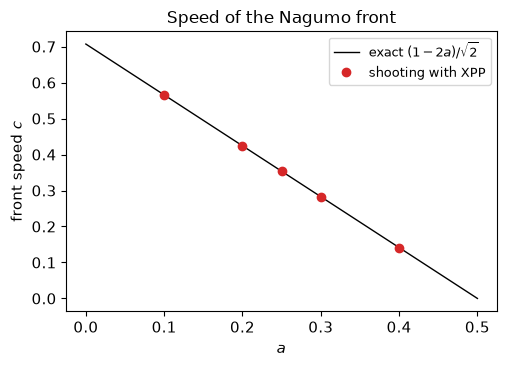

In [24]:
avals = np.array([0.1, 0.2, 0.25, 0.3, 0.4])
cs = np.array([front_speed(a) for a in avals])
exact = (1 - 2 * avals) / np.sqrt(2)
print("   a     shooting       exact (1-2a)/sqrt(2)")
for a, c, e in zip(avals, cs, exact):
    print(f"  {a:4.2f}  {c:.10f}  {e:.10f}")

fig, ax = plt.subplots(figsize=(5.2, 3.8))
aa = np.linspace(0, 0.5, 50)
ax.plot(aa, (1 - 2 * aa) / np.sqrt(2), "k-", lw=1, label=r"exact $(1 - 2a)/\sqrt{2}$")
ax.plot(avals, cs, "o", color="tab:red", label="shooting with XPP")
ax.set(xlabel="$a$", ylabel="front speed $c$", title="Speed of the Nagumo front")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "speed_vs_a.png")

### The heteroclinic orbit and the front profile ($a = 0.25$)

The orbit is kept up to where it nears $(0, 0)$. Along Huxley's front
$v = u' = -u(1-u)/\sqrt{2}$; the dashed orbits are the misses. For the
profile, $z$ is shifted so that $u = 1/2$ at $z = 0$.

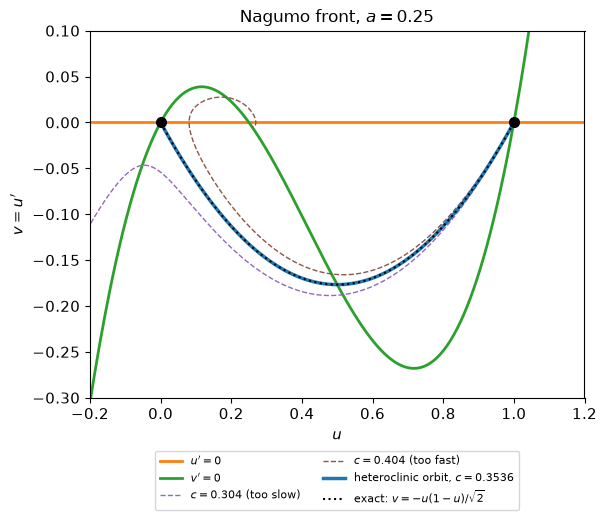

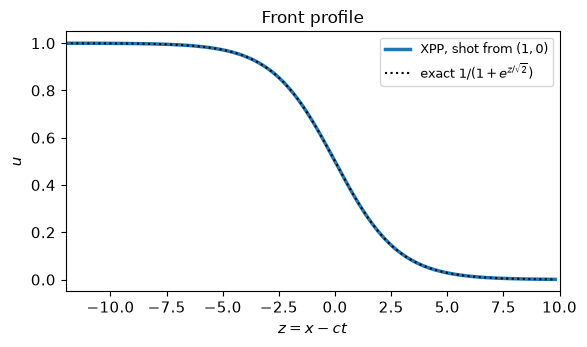

In [25]:
u, v, z = tr0["u"], tr0["v"], tr0.t
on = np.arange(len(u)) <= np.argmax(u < 1e-3)
fig, ax = plt.subplots(figsize=(6.2, 5.4))
uu = np.linspace(-0.2, 1.2, 300)
ax.axhline(0, color="tab:orange", lw=2, label="$u' = 0$")
ax.plot(uu, -uu * (1 - uu) * (uu - A0) / c0, color="tab:green", lw=2, label="$v' = 0$")
for (lab, tr), col in zip(misses.items(), ("tab:purple", "tab:brown")):
    ax.plot(tr["u"], tr["v"], "--", lw=1, color=col, label=lab)
ax.plot(u[on], v[on], color="tab:blue", lw=2.5, label=f"heteroclinic orbit, $c = {c0:.4f}$")
ax.plot(uu[(uu >= 0) & (uu <= 1)], -uu[(uu >= 0) & (uu <= 1)] * (1 - uu[(uu >= 0) & (uu <= 1)]) / np.sqrt(2),
        "k:", lw=1.5, label=r"exact: $v = -u(1-u)/\sqrt{2}$")
ax.plot([0, 1], [0, 0], "ko", ms=7)
ax.set(xlim=(-0.2, 1.2), ylim=(-0.3, 0.1), xlabel="$u$", ylabel="$v = u'$", title=f"Nagumo front, $a = {A0}$")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

k = np.argmax(u < 0.5)
z0 = z[k - 1] + (0.5 - u[k - 1]) / (u[k] - u[k - 1]) * (z[k] - z[k - 1])
zs = z - z0
profile = 1 / (1 + np.exp(zs / np.sqrt(2)))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(zs[on], u[on], color="tab:blue", lw=2.5, label="XPP, shot from $(1, 0)$")
ax.plot(zs[on], profile[on], "k:", lw=1.5, label=r"exact $1/(1 + e^{z/\sqrt{2}})$")
ax.set(xlim=(-12, 10), xlabel="$z = x - ct$", ylabel="$u$", title="Front profile")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "profile.png")

### Checks

* The speed for each $a$ against $c = (1 - 2a)/\sqrt{2}$. The bisection pins
  $c$ to $10^{-12}$; what is left comes from the start $\delta$ off the saddle
  and the Runge–Kutta step ($dt = 0.05$), both far below $10^{-6}$.
* At that speed the eigenvalues at $(1, 0)$ solve
  $\lambda^2 + c\lambda - (1 - a) = 0$, whose positive root is $1/\sqrt{2}$ for
  every $a$ (the front decays like $e^{-z/\sqrt{2}}$).
* Along the orbit $v = -u(1-u)/\sqrt{2}$ exactly, and the profile is the
  logistic curve $1/(1 + e^{z/\sqrt{2}})$. Runge–Kutta with $dt = 0.05$ has a
  global error of order $dt^4 \approx 6\times10^{-6}$: we allow $10^{-5}$.

In [26]:
for a, c, e in zip(avals, cs, exact):
    check(f"speed at a = {a} vs (1-2a)/sqrt(2) (exact)", c, e, 1e-6)
check("unstable eigenvalue at (1, 0) = 1/sqrt(2) (exact)", lam0, 1 / np.sqrt(2), 1e-6)
check("largest |v + u(1-u)/sqrt(2)| on the orbit", np.abs(v[on] + u[on] * (1 - u[on]) / np.sqrt(2)).max(), 0, 1e-5)
check("largest |u(z) - exact profile|", np.abs(u[on] - profile[on]).max(), 0, 1e-5)
checks_done()

  ok   speed at a = 0.1 vs (1-2a)/sqrt(2) (exact): 0.565685 (expected 0.565685)
  ok   speed at a = 0.2 vs (1-2a)/sqrt(2) (exact): 0.424264 (expected 0.424264)
  ok   speed at a = 0.25 vs (1-2a)/sqrt(2) (exact): 0.353553 (expected 0.353553)
  ok   speed at a = 0.3 vs (1-2a)/sqrt(2) (exact): 0.282843 (expected 0.282843)
  ok   speed at a = 0.4 vs (1-2a)/sqrt(2) (exact): 0.141421 (expected 0.141421)
  ok   unstable eigenvalue at (1, 0) = 1/sqrt(2) (exact): 0.707107 (expected 0.707107)
  ok   largest |v + u(1-u)/sqrt(2)| on the orbit: 2.10696e-08 (expected 0)
  ok   largest |u(z) - exact profile|: 3.20219e-07 (expected 0)

19_nagumo-front: 8/8 checks passed


## Summary

All checks of this notebook:

In [27]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

16_morris-lecar-bifurcation                8/8
17_morris-lecar-homoclinic                 6/6
18_interacting-saddle-nodes                9/9
19_nagumo-front                            8/8

31/31 checks passed
